# UPI Transaction Fraud & Risk Prediction (India)
**Problem:** UPI handles billions of payments every month in India. Fraud is rare (about 2% here) but every missed fraud is money lost by a real person, while every false alert annoys a genuine customer. This notebook builds a machine learning model that gives each transaction a **fraud probability** and a **risk level (Low / Medium / High)**.

**Important - about the data:** real transaction-level fraud data is confidential (banks and NPCI do not publish it). `upi_transactions_india.csv` is a **synthetic** dataset of 100,000 UPI-style transactions made with `generate_data.py` (Indian states, banks, rupee amounts, UPI transaction types). Fraud was generated from known risk signals plus random noise. So the results show the *method*, not real-world fraud rates. Say this clearly when you present.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, precision_recall_curve)
#Which transaction type has the highest fraud rate?
#Do night-time transactions have more fraud?
#Is fraud higher for new devices / new payees?
#Which model finds fraud best (PR-AUC)?
#What alert threshold saves the most money?
#How do we score ONE new transaction?

Matplotlib is building the font cache; this may take a moment.


In [2]:
df=pd.read_csv("upi_transactions_india.csv")
print(df.head())
print(df.shape)
print(df.info())

   transaction_id            timestamp transaction_type merchant_category  \
0  UPI20240053348  2024-01-01 00:09:04              P2P     Peer Transfer   
1  UPI20240048990  2024-01-01 00:09:19              P2M     Entertainment   
2  UPI20240062149  2024-01-01 00:14:55         Recharge   Mobile Recharge   
3  UPI20240056401  2024-01-01 00:22:10              P2M          Shopping   
4  UPI20240075873  2024-01-01 00:25:01              P2P     Peer Transfer   

   amount_inr    sender_state          sender_bank         receiver_bank  \
0      405.64         Gujarat  State Bank of India  Punjab National Bank   
1      297.40     Maharashtra            HDFC Bank             HDFC Bank   
2      302.46          Kerala  State Bank of India         IndusInd Bank   
3     1678.41  Madhya Pradesh           ICICI Bank   State Bank of India   
4     1600.00           Delhi  State Bank of India             HDFC Bank   

  sender_age_group device_type network_type  is_new_device  is_new_payee  \
0   

In [3]:
df["fraud_flag"].value_counts()

fraud_flag
0    98006
1     1994
Name: count, dtype: int64

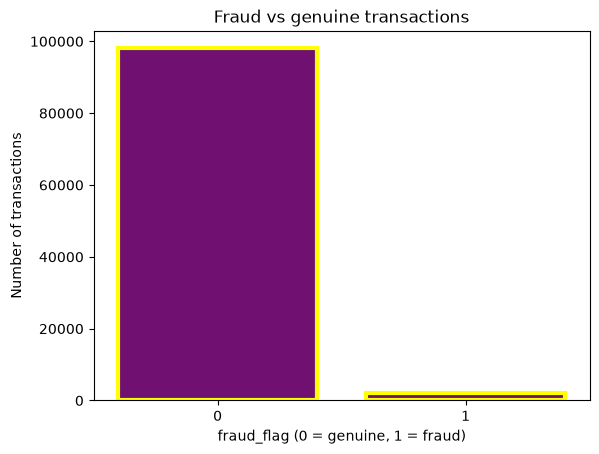

Fraud rate: 1.99%


In [4]:
sns.countplot(data=df,x="fraud_flag",color="purple",ec="Yellow",linewidth=3)
plt.title("Fraud vs genuine transactions")
plt.xlabel("fraud_flag (0 = genuine, 1 = fraud)")
plt.ylabel("Number of transactions")
plt.show()
print("Fraud rate: %.2f%%" % (df["fraud_flag"].mean()*100))

Only about 2 in 100 transactions are fraud. A model that says "genuine" every time would be 98% accurate and useless, so **accuracy is not used here**. We use precision, recall and PR-AUC instead.

## Step 1: Data cleaning

In [5]:
df.isnull().sum().sort_values(ascending=False)

network_type               1000
sender_state                800
sender_account_age_days     500
transaction_id                0
timestamp                     0
transaction_type              0
sender_bank                   0
receiver_bank                 0
merchant_category             0
amount_inr                    0
device_type                   0
sender_age_group              0
is_new_device                 0
is_new_payee                  0
txn_count_24h                 0
failed_attempts_24h           0
avg_txn_amount_30d            0
fraud_flag                    0
dtype: int64

In [6]:
# fill missing values: numbers with median, text with mode (same approach as the hotel project)
for i in df.columns:
    if df[i].isnull().sum()>0:
        if pd.api.types.is_numeric_dtype(df[i]):
            df[i]=df[i].fillna(df[i].median())
        else:
            df[i]=df[i].fillna(df[i].mode()[0])
print("Missing values left:",df.isnull().sum().sum())

Missing values left: 0


In [7]:
print("Duplicate transaction ids:",df["transaction_id"].duplicated().sum())
df=df.drop_duplicates(subset="transaction_id").reset_index(drop=True)
df["timestamp"]=pd.to_datetime(df["timestamp"])
print(df.shape)

Duplicate transaction ids: 0
(100000, 18)


In [8]:
# keep a copy of the cleaned raw rows - used later to test single-transaction scoring
raw_df=df.copy()

## Step 2: Feature engineering

In [9]:
# time features from the timestamp
df["hour"]=df["timestamp"].dt.hour
df["day_of_week"]=df["timestamp"].dt.weekday
df["month"]=df["timestamp"].dt.month
df["is_weekend"]=(df["day_of_week"]>=5).astype(int)
df["is_night"]=(df["hour"]<=5).astype(int)

# behaviour features: how unusual is this amount for this sender?
df["amount_to_avg_ratio"]=df["amount_inr"]/df["avg_txn_amount_30d"]
df["is_round_amount"]=((df["amount_inr"]%100==0)&(df["amount_inr"]>=1000)).astype(int)
df[["hour","is_night","amount_to_avg_ratio","is_round_amount"]].head()

,hour,is_night,amount_to_avg_ratio,is_round_amount
0,0,1,0.296451,0
1,0,1,1.025093,0
2,0,1,0.648346,0
3,0,1,3.154195,0
4,0,1,2.610625,1


## Step 3: Exploratory analysis (who commits fraud, and when?)

In [10]:
#Which transaction type has the highest fraud rate?
df.groupby("transaction_type")["fraud_flag"].mean().sort_values(ascending=False)*100

transaction_type
Collect Request    15.146125
P2P                 2.002525
P2M                 1.045785
Bill Payment        1.040634
Recharge            0.404722
Name: fraud_flag, dtype: float64

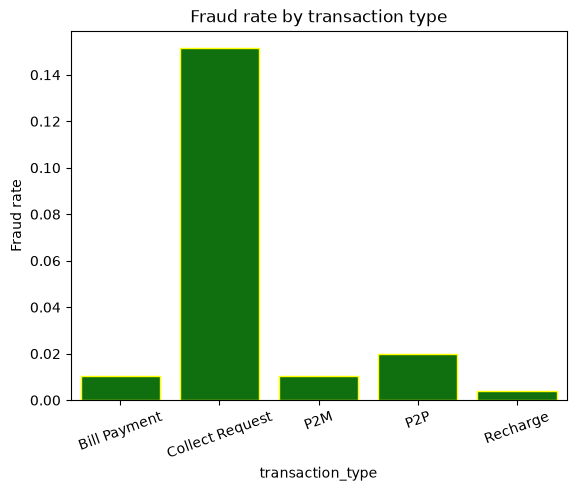

In [11]:
type_rate=df.groupby("transaction_type")["fraud_flag"].mean().reset_index()
sns.barplot(data=type_rate,x="transaction_type",y="fraud_flag",color="Green",ec="yellow")
plt.title("Fraud rate by transaction type")
plt.xticks(rotation=20)
plt.ylabel("Fraud rate")
plt.show()

is_night
0    1.835538
1    5.013034
Name: fraud_flag, dtype: float64


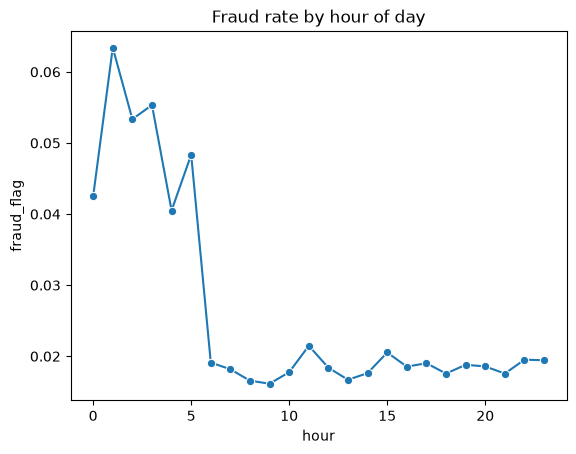

In [12]:
#Do night-time transactions have more fraud?
print(df.groupby("is_night")["fraud_flag"].mean()*100)
hour_rate=df.groupby("hour")["fraud_flag"].mean().reset_index()
sns.lineplot(data=hour_rate,x="hour",y="fraud_flag",marker="o")
plt.title("Fraud rate by hour of day")
plt.show()

In [13]:
#Is fraud higher for new devices / new payees?
print(df.groupby("is_new_device")["fraud_flag"].mean()*100)
print(df.groupby("is_new_payee")["fraud_flag"].mean()*100)

is_new_device
0    1.792644
1    6.975547
Name: fraud_flag, dtype: float64
is_new_payee
0    1.006953
1    4.967499
Name: fraud_flag, dtype: float64


In [14]:
#Which age group has the highest fraud rate?
df.groupby("sender_age_group")["fraud_flag"].mean().sort_values(ascending=False)*100

sender_age_group
60+      2.863546
46-60    1.986844
36-45    1.968144
26-35    1.894407
18-25    1.857487
Name: fraud_flag, dtype: float64

In [15]:
#Which merchant category is riskiest?
df.groupby("merchant_category")["fraud_flag"].mean().sort_values(ascending=False)*100

merchant_category
Education          5.741279
Peer Transfer      3.056359
Travel             2.246377
Online Gaming      1.234568
Healthcare         1.195219
Utilities          1.040634
Fuel               0.998573
Shopping           0.978034
Entertainment      0.657354
Food               0.534910
Grocery            0.461042
Mobile Recharge    0.404722
Name: fraud_flag, dtype: float64

In [16]:
#Does fraud differ by state? (in this synthetic data it should NOT)
state_rate=df.groupby("sender_state")["fraud_flag"].mean().sort_values(ascending=False)*100
print(state_rate.round(2))

sender_state
Assam             2.76
Haryana           2.56
Odisha            2.29
Delhi             2.15
Punjab            2.14
Maharashtra       2.12
Rajasthan         2.11
Bihar             2.07
Uttar Pradesh     2.01
Andhra Pradesh    1.98
West Bengal       1.95
Karnataka         1.94
Tamil Nadu        1.81
Gujarat           1.77
Telangana         1.75
Kerala            1.75
Madhya Pradesh    1.74
Name: fraud_flag, dtype: float64


Note: the state and bank columns carry no fraud signal in this synthetic data, so small differences between states are just random variation. Do **not** claim "state X is riskier" in your presentation.

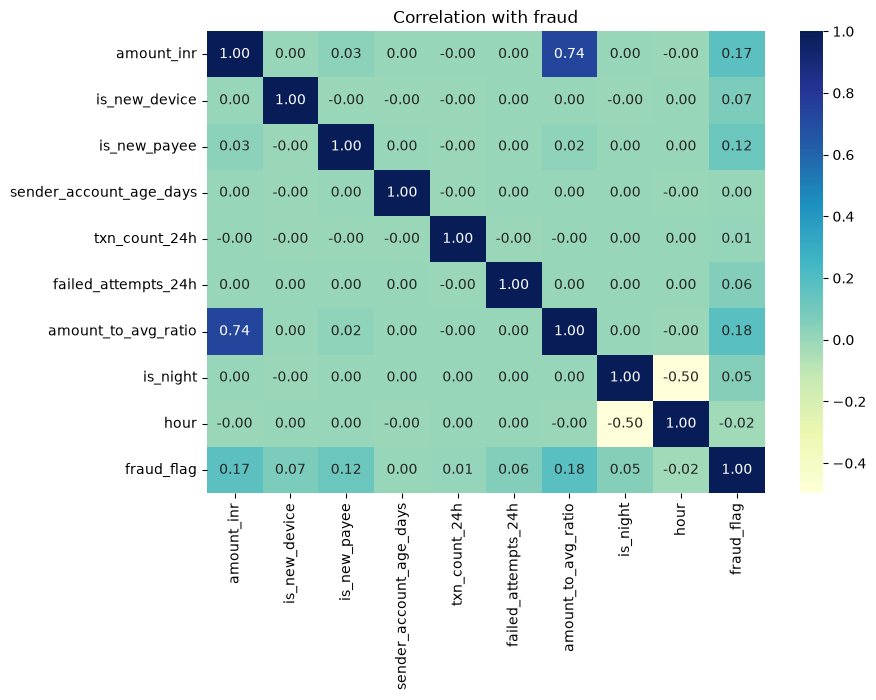

In [17]:
plt.figure(figsize=(9,6))
num_cols=["amount_inr","is_new_device","is_new_payee","sender_account_age_days","txn_count_24h",
          "failed_attempts_24h","amount_to_avg_ratio","is_night","hour","fraud_flag"]
sns.heatmap(df[num_cols].corr(),annot=True,cmap="YlGnBu",fmt=".2f")
plt.title("Correlation with fraud")
plt.show()

No single column predicts fraud strongly on its own (correlations are small). Fraud shows up as a *combination* of signals, which is why we need a machine learning model.

## Step 4: Prepare data for the model

In [18]:
# drop identifiers and the raw timestamp (we already extracted hour, day, month)
model_df=df.drop(columns=["transaction_id","timestamp"])

X=model_df.drop("fraud_flag",axis=1)
y=model_df["fraud_flag"]

# text columns -> 0/1 columns. Done BEFORE the split so train/val/test always have identical columns
X=pd.get_dummies(X,drop_first=True)
print("Number of model columns:",X.shape[1])

Number of model columns: 74


In [19]:
# 70% train, 15% validation (to choose the threshold), 15% test (final honest score)
X_train,X_temp,y_train,y_temp=train_test_split(X,y,test_size=0.30,random_state=42,stratify=y)
X_val,X_test,y_val,y_test=train_test_split(X_temp,y_temp,test_size=0.50,random_state=42,stratify=y_temp)
print(X_train.shape,X_val.shape,X_test.shape)
print("Fraud rate  train: %.2f%%  val: %.2f%%  test: %.2f%%"%(y_train.mean()*100,y_val.mean()*100,y_test.mean()*100))

(70000, 74) (15000, 74) (15000, 74)
Fraud rate  train: 1.99%  val: 1.99%  test: 1.99%


In [20]:
# scaling is only needed for Logistic Regression (tree models do not need it)
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_val_scaled=scaler.transform(X_val)
X_test_scaled=scaler.transform(X_test)

## Step 5: Train three models and compare

In [21]:
# no class_weight here: we handle the 2% imbalance by choosing the alert threshold (Step 6),
# which keeps the probabilities honest (a 5% score really means about 5% risk)
log_reg=LogisticRegression(max_iter=2000,random_state=42)
log_reg.fit(X_train_scaled,y_train)

rf=RandomForestClassifier(n_estimators=200,max_depth=12,min_samples_leaf=5,
                          random_state=42,n_jobs=-1)
rf.fit(X_train,y_train)

hgb=HistGradientBoostingClassifier(max_iter=200,learning_rate=0.1,random_state=42)
hgb.fit(X_train,y_train)
print("All three models trained")

All three models trained


In [22]:
# validation probabilities from each model
val_prob={
    "Logistic Regression":log_reg.predict_proba(X_val_scaled)[:,1],
    "Random Forest":rf.predict_proba(X_val)[:,1],
    "Gradient Boosting":hgb.predict_proba(X_val)[:,1],
}
rows=[]
for name,p in val_prob.items():
    rows.append([name,round(average_precision_score(y_val,p),4),round(roc_auc_score(y_val,p),4)])
compare=pd.DataFrame(rows,columns=["Model","PR-AUC","ROC-AUC"]).sort_values("PR-AUC",ascending=False)
print(compare)
print("Baseline PR-AUC of a random guess = fraud rate = %.4f"%y_val.mean())

                 Model  PR-AUC  ROC-AUC
1        Random Forest  0.2905   0.8594
2    Gradient Boosting  0.2604   0.8574
0  Logistic Regression  0.2339   0.8556
Baseline PR-AUC of a random guess = fraud rate = 0.0199


In [23]:
best_name=compare.iloc[0]["Model"]
print("Best model on validation set (by PR-AUC):",best_name)
models={"Logistic Regression":log_reg,"Random Forest":rf,"Gradient Boosting":hgb}
best_model=models[best_name]

Best model on validation set (by PR-AUC): Random Forest


**Why PR-AUC?** With 2% fraud, ROC-AUC looks flattering. PR-AUC (precision-recall) only rewards a model that finds the rare fraud cases *without* raising too many false alarms. A random guess scores about 0.02, so anything well above that is real signal.

## Step 6: Choose the alert threshold using money, not 0.5

In [24]:
# Business assumption (you can change these numbers):
#  - a MISSED fraud costs the transaction amount (the customer loses that money)
#  - a FALSE alert costs Rs 75 (manual review + customer friction)
FALSE_ALERT_COST=75

def total_cost(y_true,prob,amount,threshold):
    flagged=prob>=threshold
    missed_fraud=(y_true==1)&(~flagged)
    false_alert=(y_true==0)&(flagged)
    return amount[missed_fraud].sum()+FALSE_ALERT_COST*false_alert.sum()

if best_name=="Logistic Regression":
    p_val=best_model.predict_proba(X_val_scaled)[:,1]
else:
    p_val=best_model.predict_proba(X_val)[:,1]

amt_val=X_val["amount_inr"].values
y_val_arr=y_val.values
thresholds=np.arange(0.01,0.96,0.01)
costs=[total_cost(y_val_arr,p_val,amt_val,t) for t in thresholds]
best_threshold=float(thresholds[int(np.argmin(costs))])
print("Best threshold on validation set: %.2f"%best_threshold)
print("Total cost at best threshold: Rs {:,.0f}".format(min(costs)))
print("Total cost if we flag nothing:  Rs {:,.0f}".format(amt_val[y_val_arr==1].sum()))

Best threshold on validation set: 0.03
Total cost at best threshold: Rs 310,627
Total cost if we flag nothing:  Rs 1,707,379


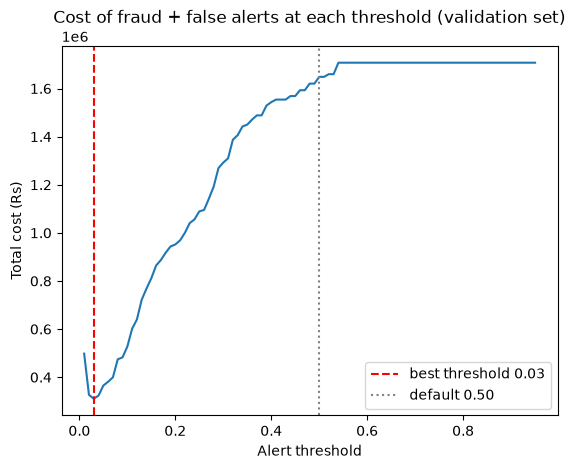

In [25]:
plt.plot(thresholds,costs)
plt.axvline(best_threshold,color="red",linestyle="--",label="best threshold %.2f"%best_threshold)
plt.axvline(0.5,color="grey",linestyle=":",label="default 0.50")
plt.xlabel("Alert threshold")
plt.ylabel("Total cost (Rs)")
plt.title("Cost of fraud + false alerts at each threshold (validation set)")
plt.legend()
plt.show()

## Step 7: Final result on the untouched test set

In [26]:
if best_name=="Logistic Regression":
    p_test=best_model.predict_proba(X_test_scaled)[:,1]
else:
    p_test=best_model.predict_proba(X_test)[:,1]

y_test_arr=y_test.values
amt_test=X_test["amount_inr"].values

for label,t in [("Default threshold 0.50",0.50),("Cost-based threshold %.2f"%best_threshold,best_threshold)]:
    pred=(p_test>=t).astype(int)
    print("---",label,"---")
    print("Precision: %.3f  Recall: %.3f  F1: %.3f"%(precision_score(y_test_arr,pred),recall_score(y_test_arr,pred),f1_score(y_test_arr,pred)))
    print(confusion_matrix(y_test_arr,pred))

print("\nTest PR-AUC: %.4f   ROC-AUC: %.4f"%(average_precision_score(y_test_arr,p_test),roc_auc_score(y_test_arr,p_test)))

--- Default threshold 0.50 ---
Precision: 1.000  Recall: 0.017  F1: 0.033
[[14701     0]
 [  294     5]]
--- Cost-based threshold 0.03 ---
Precision: 0.105  Recall: 0.739  F1: 0.184
[[12823  1878]
 [   78   221]]

Test PR-AUC: 0.2988   ROC-AUC: 0.8850


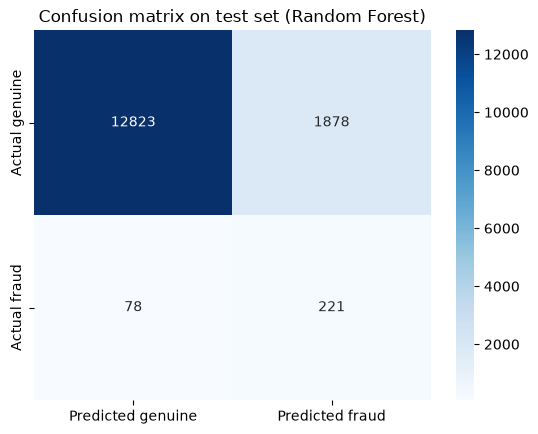

In [27]:
pred=(p_test>=best_threshold).astype(int)
cm=confusion_matrix(y_test_arr,pred)
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["Predicted genuine","Predicted fraud"],yticklabels=["Actual genuine","Actual fraud"])
plt.title("Confusion matrix on test set (%s)"%best_name)
plt.show()

In [28]:
# money impact on the test set
cost_no_model=amt_test[y_test_arr==1].sum()
cost_default=total_cost(y_test_arr,p_test,amt_test,0.50)
cost_best=total_cost(y_test_arr,p_test,amt_test,best_threshold)
print("Cost with no model:            Rs {:,.0f}".format(cost_no_model))
print("Cost at default 0.50:          Rs {:,.0f}".format(cost_default))
print("Cost at cost-based threshold:  Rs {:,.0f}".format(cost_best))
print("Saving vs no model: %.1f%%"%((cost_no_model-cost_best)/cost_no_model*100))

Cost with no model:            Rs 1,786,740
Cost at default 0.50:          Rs 1,698,810
Cost at cost-based threshold:  Rs 306,335
Saving vs no model: 82.9%


These rupee figures come from synthetic data and an assumed Rs 75 false-alert cost, so treat them as an illustration of the method.

## Step 8: Which signals drive fraud?

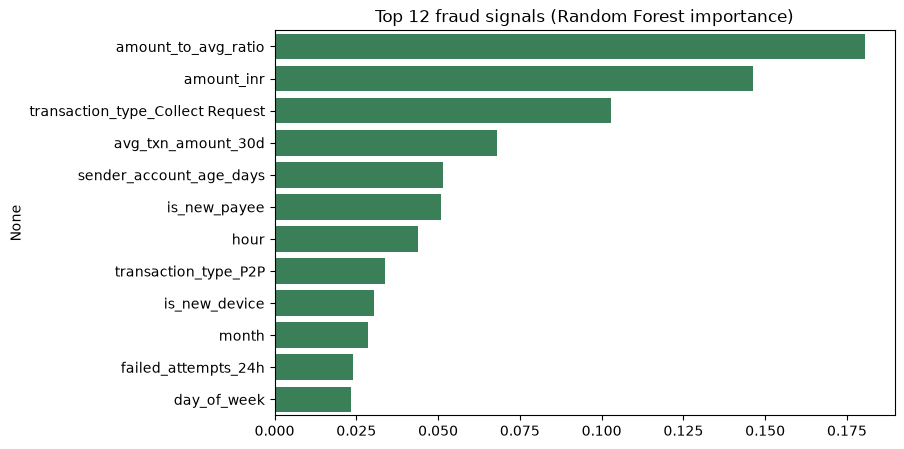

amount_to_avg_ratio                 0.1805
amount_inr                          0.1462
transaction_type_Collect Request    0.1028
avg_txn_amount_30d                  0.0680
sender_account_age_days             0.0514
is_new_payee                        0.0509
hour                                0.0440
transaction_type_P2P                0.0337
is_new_device                       0.0305
month                               0.0284
failed_attempts_24h                 0.0241
day_of_week                         0.0232
dtype: float64


In [29]:
imp=pd.Series(rf.feature_importances_,index=X.columns).sort_values(ascending=False).head(12)
plt.figure(figsize=(8,5))
sns.barplot(x=imp.values,y=imp.index,color="seagreen")
plt.title("Top 12 fraud signals (Random Forest importance)")
plt.show()
print(imp.round(4))

## Step 9: Save the model

In [30]:
# scoring one transaction at a time is faster (and quieter) without parallel workers
if hasattr(best_model,"n_jobs"):
    best_model.n_jobs=1
joblib.dump(best_model,"upi_fraud_model.pkl",compress=3)
joblib.dump(list(X.columns),"feature_names.pkl")
joblib.dump({"threshold":best_threshold,"model_name":best_name},"threshold_info.pkl")
if best_name=="Logistic Regression":
    joblib.dump(scaler,"scaler.pkl")
print("Saved model for:",best_name,"| threshold:",best_threshold)

Saved model for: Random Forest | threshold: 0.03


## Step 10: Score ONE new transaction (what a real system does)

In [31]:
feature_names=X.columns.tolist()
numeric_inputs=["amount_inr","is_new_device","is_new_payee","sender_account_age_days","txn_count_24h",
                "failed_attempts_24h","avg_txn_amount_30d","hour","day_of_week","month",
                "is_weekend","is_night","amount_to_avg_ratio","is_round_amount"]
text_inputs=["transaction_type","merchant_category","sender_state","sender_bank","receiver_bank",
             "sender_age_group","device_type","network_type"]

def predict_transaction(t):
    """t = dict with the raw fields of one UPI transaction. Returns probability and risk level."""
    t=dict(t)
    ts=pd.to_datetime(t["timestamp"])
    t["hour"]=ts.hour
    t["day_of_week"]=ts.weekday()
    t["month"]=ts.month
    t["is_weekend"]=int(ts.weekday()>=5)
    t["is_night"]=int(ts.hour<=5)
    t["amount_to_avg_ratio"]=t["amount_inr"]/t["avg_txn_amount_30d"]
    t["is_round_amount"]=int(t["amount_inr"]%100==0 and t["amount_inr"]>=1000)

    row=pd.DataFrame(0.0,index=[0],columns=feature_names)   # all columns start at 0
    for c in numeric_inputs:
        row.at[0,c]=t[c]
    for c in text_inputs:                                    # set e.g. transaction_type_P2P = 1
        name=c+"_"+str(t[c])
        if name in row.columns:                              # a missing column = the dropped baseline
            row.at[0,name]=1.0

    if best_name=="Logistic Regression":
        row_in=scaler.transform(row)
    else:
        row_in=row
    prob=float(best_model.predict_proba(row_in)[0,1])

    if prob>=best_threshold:
        level="HIGH"
    elif prob>=best_threshold/2:
        level="MEDIUM"
    else:
        level="LOW"
    return prob,level

In [32]:
# check: scoring a raw row one-by-one must give the SAME probability as the big test matrix
test_pos=list(X_test.index[:300])
test_prob_lookup=dict(zip(X_test.index,p_test))
max_diff=0
for idx in test_pos:
    raw=raw_df.loc[idx].to_dict()
    p,_=predict_transaction(raw)
    max_diff=max(max_diff,abs(p-test_prob_lookup[idx]))
print("Max difference between single scoring and batch scoring:",max_diff)

Max difference between single scoring and batch scoring: 5.551115123125783e-17


In [33]:
examples={
 "Normal grocery payment (daytime, known device)":{
    "timestamp":"2026-10-09 18:30:00","transaction_type":"P2M","merchant_category":"Grocery","amount_inr":640.0,
    "sender_state":"Maharashtra","sender_bank":"HDFC Bank","receiver_bank":"State Bank of India",
    "sender_age_group":"26-35","device_type":"Android","network_type":"4G","is_new_device":0,"is_new_payee":0,
    "sender_account_age_days":1200,"txn_count_24h":2,"failed_attempts_24h":0,"avg_txn_amount_30d":700.0},
 "Big transfer to a new payee in the evening":{
    "timestamp":"2026-10-09 20:10:00","transaction_type":"P2P","merchant_category":"Peer Transfer","amount_inr":25000.0,
    "sender_state":"Karnataka","sender_bank":"ICICI Bank","receiver_bank":"Axis Bank",
    "sender_age_group":"36-45","device_type":"Android","network_type":"WiFi","is_new_device":0,"is_new_payee":1,
    "sender_account_age_days":800,"txn_count_24h":3,"failed_attempts_24h":0,"avg_txn_amount_30d":1800.0},
 "Collect request at 2 AM, new device, failed attempts, senior citizen":{
    "timestamp":"2026-10-10 02:15:00","transaction_type":"Collect Request","merchant_category":"Peer Transfer","amount_inr":49000.0,
    "sender_state":"Uttar Pradesh","sender_bank":"State Bank of India","receiver_bank":"Yes Bank",
    "sender_age_group":"60+","device_type":"Android","network_type":"4G","is_new_device":1,"is_new_payee":1,
    "sender_account_age_days":2500,"txn_count_24h":6,"failed_attempts_24h":3,"avg_txn_amount_30d":900.0},
}
for name,t in examples.items():
    p,level=predict_transaction(t)
    print("%-72s fraud probability: %5.1f%%   risk: %s"%(name,p*100,level))

Normal grocery payment (daytime, known device)                           fraud probability:   0.3%   risk: LOW
Big transfer to a new payee in the evening                               fraud probability:  22.6%   risk: HIGH
Collect request at 2 AM, new device, failed attempts, senior citizen     fraud probability:  53.8%   risk: HIGH


## Conclusion
- Cleaned and explored 100,000 UPI-style transactions and engineered time and behaviour features (night, amount vs the sender's normal, round amounts).
- Compared Logistic Regression, Random Forest and Gradient Boosting using **PR-AUC**, because fraud is only about 2% of transactions.
- Chose the alert threshold by **rupee cost** (missed fraud vs false alert) on a validation set, and reported the final result on a separate test set.
- Saved the model and added `predict_transaction()` that scores one new transaction and returns a probability and a Low / Medium / High risk level.
- **Limits:** the data is synthetic, so real-world performance is unknown. Next steps: test on real labelled data (with permission), add more behaviour features, and monitor drift after deployment.